AMMONIA ABSORPTION - McCABE-THIELE METHOD
Temperature                 = 288.15 K
Gas volumetric flow         = 0.0710 m^3/s
Total gas flow              = 0.003003 kmol/s
Air flow                    = 0.002703 kmol/s
Air mass flow               = 0.078292 kg/s

--- GAS COMPOSITION ---
Y1 = 0.065317 kg NH3/kg air
Y2 = 0.009797 kg NH3/kg air

--- MINIMUM SOLVENT RATE ---
X1*                         = 0.063597
(L/G)_min                   = 0.872981
L_min                       = 0.068347 kg/s

--- ACTUAL SOLVENT RATE ---
L/G                         = 1.309471
L                           = 0.102521 kg/s
L                           = 0.005691 kmol/s

--- NUMBER OF STAGES ---
Theoretical stages          = 2.472
Whole theoretical stages    = 3

--- STAGE STEPPING ---
Stage      Y_start       X_eq        Y_next
  1       0.00980      0.01480      0.02917
  2       0.02917      0.03280      0.05275
  3       0.05275      0.05312      0.07936


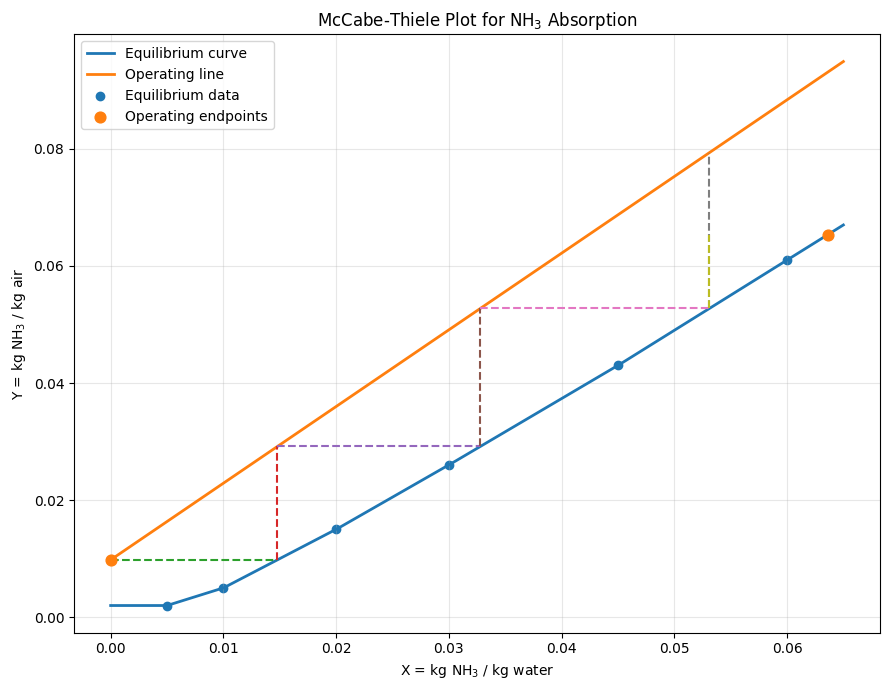

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. GIVEN DATA
V = 0.071                 # m^3/s
T = 15 + 273.15           # K
P = 1.0                   # atm

y_NH3 = 0.10              # mole fraction NH3
removal = 0.85

MW_NH3 = 17.03            # kg/kmol
MW_air = 28.97            # kg/kmol
MW_water = 18.015         # kg/kmol

# Equilibrium data
X_eq = np.array([0.005, 0.010, 0.020, 0.030, 0.045, 0.060])
Y_eq = np.array([0.002, 0.005, 0.015, 0.026, 0.043, 0.061])

# 2. GAS FLOW RATE USING IDEAL GAS LAW

# Convert m3/s to L/s
V_L = V * 1000

# R in L atm/(mol K)
R = 0.082057

# Total molar gas flow, mol/s
n_total_mol = P * V_L / (R * T)

# Convert to kmol/s
n_total = n_total_mol / 1000

# Air is 90 mol%
G_kmol = n_total * (1 - y_NH3)

# Convert air flow to kg/s
G = G_kmol * MW_air


# 3. CONVERT GAS COMPOSITION TO MASS RATIO

# Y = kg NH3 / kg air
Y1 = (y_NH3 / (1 - y_NH3)) * (MW_NH3 / MW_air)

# 85% removal means 15% NH3 remains
Y2 = (1 - removal) * Y1

# Solute-free entering liquid
X2 = 0.0


# 4. FIND X* CORRESPONDING TO Y1

# Y1 is slightly greater than the maximum tabulated Y.
# Therefore linearly extrapolate using the last two points.

slope_last = (
    (Y_eq[-1] - Y_eq[-2]) /
    (X_eq[-1] - X_eq[-2])
)

X1_star = X_eq[-1] + (Y1 - Y_eq[-1]) / slope_last


# 5. MINIMUM SOLVENT RATE

L_G_min = (Y1 - Y2) / (X1_star - X2)

L_min = L_G_min * G

# Actual solvent = 50% excess
L = 1.5 * L_min

# Convert to kmol/s
L_kmol = L / MW_water

# 6. OPERATING LINE

L_G = L / G

def operating_line(X):
    return Y2 + L_G * (X - X2)


# 7. EQUILIBRIUM FUNCTION

def equilibrium_X(Y):
    """
    Find X corresponding to a given Y using
    linear interpolation/extrapolation.
    """

    if Y <= Y_eq[0]:
        # Extrapolation below first point
        slope = (Y_eq[1] - Y_eq[0]) / (X_eq[1] - X_eq[0])
        return X_eq[0] + (Y - Y_eq[0]) / slope

    elif Y >= Y_eq[-1]:
        # Extrapolation above last point
        slope = (Y_eq[-1] - Y_eq[-2]) / (X_eq[-1] - X_eq[-2])
        return X_eq[-1] + (Y - Y_eq[-1]) / slope

    else:
        return np.interp(Y, Y_eq, X_eq)


# 8. McCABE-THIELE STAGE STEPPING

Y_current = Y2

stages = []

for stage in range(1, 20):

    # Horizontal step to equilibrium curve
    X_equilibrium = equilibrium_X(Y_current)

    # Vertical step to operating line
    Y_next = operating_line(X_equilibrium)

    stages.append(
        [stage, Y_current, X_equilibrium, Y_next]
    )

    # Stop when inlet gas composition is reached
    if Y_next >= Y1:
        break

    Y_current = Y_next


# 9. CALCULATE FRACTIONAL STAGE

# If last step crosses Y1, calculate fraction of final stage
if len(stages) > 0:

    Y_before = stages[-1][1]
    Y_after = stages[-1][3]

    if Y_after > Y1:
        fraction = (Y1 - Y_before) / (Y_after - Y_before)
        N_stages = (len(stages) - 1) + fraction
    else:
        N_stages = len(stages)

else:
    N_stages = 0


# 10. PRINT RESULTS

#print("=" * 60)
print("AMMONIA ABSORPTION - McCABE-THIELE METHOD")
#print("=" * 60)

print(f"Temperature                 = {T:.2f} K")
print(f"Gas volumetric flow         = {V:.4f} m^3/s")
print(f"Total gas flow              = {n_total:.6f} kmol/s")
print(f"Air flow                    = {G_kmol:.6f} kmol/s")
print(f"Air mass flow               = {G:.6f} kg/s")

print("\n--- GAS COMPOSITION ---")
print(f"Y1 = {Y1:.6f} kg NH3/kg air")
print(f"Y2 = {Y2:.6f} kg NH3/kg air")

print("\n--- MINIMUM SOLVENT RATE ---")
print(f"X1*                         = {X1_star:.6f}")
print(f"(L/G)_min                   = {L_G_min:.6f}")
print(f"L_min                       = {L_min:.6f} kg/s")

print("\n--- ACTUAL SOLVENT RATE ---")
print(f"L/G                         = {L_G:.6f}")
print(f"L                           = {L:.6f} kg/s")
print(f"L                           = {L_kmol:.6f} kmol/s")

print("\n--- NUMBER OF STAGES ---")
print(f"Theoretical stages          = {N_stages:.3f}")
print(f"Whole theoretical stages    = {int(np.ceil(N_stages))}")

print("\n--- STAGE STEPPING ---")
print("Stage      Y_start       X_eq        Y_next")

for row in stages:
    print(
        f"{int(row[0]):3d}    "
        f"{row[1]:10.5f}   "
        f"{row[2]:10.5f}   "
        f"{row[3]:10.5f}"
    )


# 11. McCABE-THIELE PLOT


# Create smooth equilibrium curve
X_plot = np.linspace(0, max(X1_star, 0.065), 500)

# Interpolate equilibrium curve
Y_plot = np.interp(
    X_plot,
    X_eq,
    Y_eq
)

# For X above 0.06, extrapolate using last slope
last_slope = (
    (Y_eq[-1] - Y_eq[-2]) /
    (X_eq[-1] - X_eq[-2])
)

mask = X_plot > X_eq[-1]

Y_plot[mask] = (
    Y_eq[-1]
    + last_slope * (X_plot[mask] - X_eq[-1])
)

# Operating line
Y_op = operating_line(X_plot)


# 12. PLOT


plt.figure(figsize=(9, 7))

# Equilibrium curve
plt.plot(
    X_plot,
    Y_plot,
    linewidth=2,
    label="Equilibrium curve"
)

# Operating line
plt.plot(
    X_plot,
    Y_op,
    linewidth=2,
    label="Operating line"
)

# Plot equilibrium data points
plt.scatter(
    X_eq,
    Y_eq,
    label="Equilibrium data"
)

# McCabe-Thiele staircase


Y_current = Y2

for i, row in enumerate(stages):

    stage = int(row[0])
    X_horizontal = row[2]
    Y_next = row[3]

    # Horizontal step
    plt.plot(
        [0 if i == 0 else stages[i-1][2],
         X_horizontal],
        [Y_current, Y_current],
        linestyle="--"
    )

    # Vertical step
    plt.plot(
        [X_horizontal, X_horizontal],
        [Y_current, Y_next],
        linestyle="--"
    )

    # If final step crosses Y1,
    # mark required inlet condition
    if Y_next >= Y1:
        plt.plot(
            [X_horizontal, X_horizontal],
            [Y_current, Y1],
            linestyle="--"
        )
        break

    Y_current = Y_next


# Feed and outlet points
plt.scatter(
    [0, X1_star],
    [Y2, Y1],
    s=60,
    zorder=5,
    label="Operating endpoints"
)

plt.xlabel("X = kg NH$_3$ / kg water")
plt.ylabel("Y = kg NH$_3$ / kg air")

plt.title(
    "McCabe-Thiele Plot for NH$_3$ Absorption"
)

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()